### Weniger Bias, mehr Rendite? Hybrides Modell aus Large Language Models und Machine Learning zur Analyse von Earnings Calls
**Bachelorarbeit an der Universität St.Gallen (HSG)**\
[© 2026 Ruben Cardell](https://polyformproject.org/licenses/noncommercial/1.0.0)

---

# Machine Learning – Versuch 3 (Kombination der Versuche 1 und 2)

Versuch 3 führt die Merkmale der Versuche 1 und 2 zusammen (36 Merkmale) und
prüft damit, ob die beiden Repräsentationen komplementäre Information tragen.
Ein eigener LLM-Lauf findet nicht statt. Die Direktprognosen des LLM gehen
hier nicht als Features ein, weshalb die Vergleichsgrösse der Direktprognose
in diesem Notebook entfällt. Zielvariable ist die um den Quartalsmittelwert
bereinigte Kursentwicklung über die 90 Tage nach dem Earnings Call.

Ablauf des Notebooks:

1. Datensatz laden
2. Datenexploration
3. Datenaufbereitung und chronologischer Train-Test-Split
4. Long-Short Rendite als Gütekriterium sowie die beiden Vergleichsgrössen
5. Aufbau des Hyperparameter-Tunings
6.–10. Training und Auswertung der Modelle: Lineare Regression, Random Forest,
   XGBoost, LightGBM und Neural Network, jeweils in Standardkonfiguration und
   mit getunten Hyperparametern
11. Vorhersagen und Modelle speichern

**Versionsbezeichnungen im Code:** `v3` = Versuch 1, `v4` = Versuch 2,
`v5` = Versuch 3.

## 1 Datensatz laden

In [1]:
# Bibliotheken für Auswertung und Grafiken
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Google Drive einbinden (Ausführung in Google Colab)
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Datensatz aus dem Postprocessing laden; der Index ist die episode_id
# im Format TICKER_JAHR_QUARTAL
df = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/ml_data_v5.csv', index_col="episode_id")

In [4]:
# Beobachtungen ohne Zielvariable entfernen (v.a. Earnings Calls aus 2025,
# deren 90-Tage-Fenster noch nicht abgeschlossen ist)
df = df.dropna(axis = 0, subset = ["move_next_qtr"])

In [5]:
# Spalten, Datentypen und fehlende Werte prüfen
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 28934 entries, AAL_2007_Q3 to ZTS_2024_Q4
Data columns (total 37 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   relevant_mean    28934 non-null  float64
 1   relevant_min     28934 non-null  float64
 2   relevant_max     28934 non-null  float64
 3   clear_mean       28934 non-null  float64
 4   clear_min        28934 non-null  float64
 5   clear_max        28934 non-null  float64
 6   optimistic_mean  28934 non-null  float64
 7   optimistic_min   28934 non-null  float64
 8   optimistic_max   28934 non-null  float64
 9   specific_mean    28934 non-null  float64
 10  specific_min     28934 non-null  float64
 11  specific_max     28934 non-null  float64
 12  cautious_mean    28934 non-null  float64
 13  cautious_min     28934 non-null  float64
 14  cautious_max     28934 non-null  float64
 15  assertive_mean   28934 non-null  float64
 16  assertive_min    28934 non-null  float64
 17  a

## 2 Datenexploration

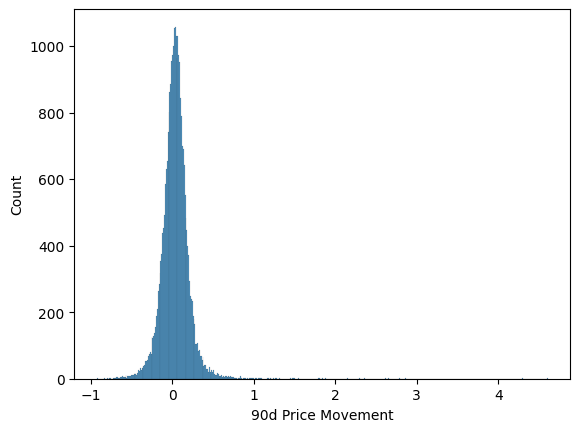

In [ ]:
# Verteilung der tatsächlichen 90-Tage-Kursentwicklung
sns.histplot(df["move_next_qtr"])
plt.xlabel("90d Price Movement")
plt.show()

In [6]:
# Ausreisser entfernen: einzelne Werte reichen von −100% bis +400%. Behalten
# werden die Beobachtungen zwischen dem 2.5ten und 97.5ten Perzentil.
s = df["move_next_qtr"]

lower, upper = s.quantile([0.025, 0.975])

print(f"Lower bound (2.5th percentile): {lower:.4f}")
print(f"Upper bound (97.5th percentile): {upper:.4f}")
print("--")

df_filtered = df[(df['move_next_qtr'] >= lower) & (df['move_next_qtr'] <= upper)].copy()

print(f"Original rows: {len(df)}")
print(f"Filtered rows: {len(df_filtered)}")
print(f"Removed: {len(df) - len(df_filtered)}")

Lower bound (2.5th percentile): -0.2847
Upper bound (97.5th percentile): 0.3588
--
Original rows: 28934
Filtered rows: 27486
Removed: 1448


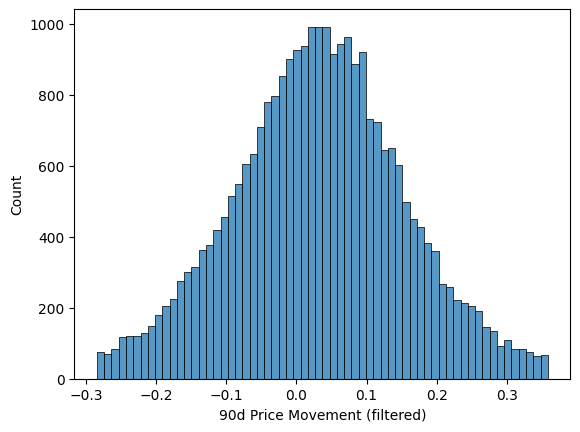

In [ ]:
# Verteilung nach Entfernen der Ausreisser
sns.histplot(df_filtered["move_next_qtr"])
plt.xlabel("90d Price Movement (filtered)")
plt.show()

## 3 Datenaufbereitung

In [7]:
# Berichtsperiode aus der episode_id ableiten, z.B. "AAL_2007_Q3"
df_filtered[['ticker', 'year', 'quarter']] = df_filtered.index.to_series().str.split('_', expand=True)
df_filtered['period'] = df_filtered['year'] + '_' + df_filtered['quarter']

# Zielvariable je Quartal um den Mittelwert bereinigen: prognostiziert wird die
# Entwicklung eines Unternehmens relativ zu den übrigen Unternehmen desselben
# Quartals, nicht die vom Gesamtmarkt geprägte absolute Rendite.
df_filtered['y_relative'] = df_filtered['move_next_qtr'] - df_filtered.groupby('period')['move_next_qtr'].transform('mean')

In [ ]:
# Anzahl Beobachtungen je Quartal prüfen
print(df_filtered['period'].value_counts().sort_index())

period
2005_Q4     39
2006_Q1     48
2006_Q2     53
2006_Q3     69
2006_Q4     74
          ... 
2024_Q3    475
2024_Q4    435
2025_Q1     82
2025_Q2     48
2025_Q3     17
Name: count, Length: 80, dtype: int64


### 3.1 Train-Test-Split

Die Aufteilung erfolgt chronologisch: Earnings Calls bis einschliesslich 2021
bilden die Trainingsdaten, ab 2022 die Testdaten. Eine zufällige Aufteilung wäre
nicht zulässig, da Beobachtungen desselben Quartals sonst in beide Mengen fallen
und das Modell aus zeitgleichen Kursentwicklungen anderer Unternehmen lernen
würde.

In [8]:
# Zielvariable und Hilfsspalten sind keine Features und werden entfernt. Die
# Direktprognosen des LLM wurden bereits beim Zusammenführen der Datensätze
# entfernt (siehe "POSTprocessing.ipynb")
cols_to_drop = ["move_next_qtr", 'ticker', 'year', 'quarter', 'period', 'y_relative']

df_train = df_filtered[df_filtered["year"] <= "2021"]
df_test = df_filtered[df_filtered["year"] >= "2022"]

X_train = df_train.drop(cols_to_drop, axis=1)
X_test = df_test.drop(cols_to_drop, axis=1)

y_train = df_train["y_relative"]
y_test = df_test["y_relative"]

In [9]:
# Verwendete Features kontrollieren
print(X_train.columns)

Index(['relevant_mean', 'relevant_min', 'relevant_max', 'clear_mean',
       'clear_min', 'clear_max', 'optimistic_mean', 'optimistic_min',
       'optimistic_max', 'specific_mean', 'specific_min', 'specific_max',
       'cautious_mean', 'cautious_min', 'cautious_max', 'assertive_mean',
       'assertive_min', 'assertive_max', 'valence_mean', 'valence_min',
       'valence_max', 'arousal_mean', 'arousal_min', 'arousal_max',
       'dominance_mean', 'dominance_min', 'dominance_max', 'relevant', 'clear',
       'optimistic', 'specific', 'cautious', 'assertive', 'valence', 'arousal',
       'dominance'],
      dtype='object')


## 4 Long-Short Rendite

Neben dem RMSE dient die Long-Short Rendite als Gütekriterium, da die
Kursentwicklung stark von makroökonomischen Faktoren abhängt, die nicht aus
Earnings Calls hervorgehen. Sie misst, ob das Modell die Unternehmen eines
Quartals in der richtigen Reihenfolge einordnet.

In [10]:
# Fehlermasse als ergänzende Kennzahlen zur Long-Short Rendite
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

In [35]:
def long_short_returns(y_pred, y_test, actual_full, top_pct=0.2, verbose=True):
    """Berechnet die Long-Short Rendite eines Modells sowie ergänzende Fehlermasse.

    Je Quartal werden alle Unternehmen absteigend nach der vorhergesagten
    Kursentwicklung sortiert. Auf das obere Quantil wird eine Long-Position, auf
    das untere eine Short-Position simuliert; die mittleren 60% werden ignoriert,
    da die Vorhersagen dort nur schwach variieren. Die Quartalsrenditen werden
    anschliessend je Jahr aufgezinst und auf ein volles Jahr hochgerechnet, da
    am Anfang und Ende des Datensatzes nicht alle Quartale vorliegen.

    top_pct: Anteil je Korb (0.2 = oberste und unterste 20%).
    verbose=True gibt die Kennzahlen aus, verbose=False gibt sie zurück
    (so wird die Funktion auch als Scorer im Hyperparameter-Tuning verwendet).
    """
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    y_pred = pd.Series(y_pred, index=y_test.index)  # episode_id an die Vorhersagen anhängen
    actual = actual_full.loc[y_test.index]  # tatsächliche Renditen derselben episode_ids

    df = pd.DataFrame({'pred': y_pred, 'actual': actual})  # Vorhersage und Realität in einer Tabelle

    parts = df.index.to_series().str.split('_', expand=True)  # "AAL_2019_Q2" -> ['AAL', '2019', 'Q2']
    df['period'] = parts[1] + '_' + parts[2]  # als "2019_Q2" für die Gruppierung je Quartal

    results = {}  # eine Long-Short Rendite je Quartal
    for period, g in df.groupby('period'):  # über die Quartale iterieren
        g = g.sort_values('pred', ascending=False)  # nach Vorhersage sortieren, höchste zuerst
        n = max(1, int(len(g) * top_pct))  # Korbgrösse (oberste/unterste top_pct%), mindestens 1 Titel

        long_ret = g['actual'].iloc[:n].mean()  # durchschnittliche Rendite des Long-Korbs
        short_ret = g['actual'].iloc[-n:].mean()  # durchschnittliche Rendite des Short-Korbs

        results[period] = long_ret - short_ret  # Differenz als Long-Short Rendite des Quartals

    q_ret = pd.Series(results).sort_index()  # Quartalsrenditen in chronologischer Reihenfolge

    years = q_ret.index.str.split('_').str[0]  # Jahr aus dem Quartalslabel ("2019_Q2" -> "2019")

    def compound_and_annualize(group):
        n_quarters = len(group)  # tatsächlich vorhandene Quartale dieses Jahres
        compounded = (1 + group).prod() - 1  # vorhandene Quartale aufzinsen
        return (1 + compounded) ** (4 / n_quarters) - 1  # auf vier Quartale hochrechnen

    y_ret = q_ret.groupby(years).apply(compound_and_annualize)  # eine Jahresrendite je Jahr

    if verbose:
        print(f"Avg return/quarter: {q_ret.mean():.1%}")           # mittlere Rendite je Quartal
        print(f"Avg return/year: {y_ret.mean():.1%}")              # mittlere Rendite je Jahr
        print(f"Win rate: {(q_ret > 0).mean():.1%}")               # Anteil Quartale mit positiver Rendite
        print(f"Cumulative return: {(1 + q_ret).prod() - 1:.1%}")  # alle Quartale aufgezinst
        print(f"Std Dev: {q_ret.std():.2f}")                       # Volatilität der Quartalsrenditen
        print(f"Sharpe: {q_ret.mean() / q_ret.std():.2f}")         # Sharpe-ähnlicher Quotient (risikofreier Zins = 0)
        print(f"RMSE: {rmse:.4f}")
        print(f"MAE: {mae:.4f}")

    else:
        return q_ret, y_ret, rmse, mae

### 4.1 Vergleichsgrösse: Zufallsprognose

Gezogen wird aus einer Normalverteilung mit Mittelwert und Standardabweichung
der Trainingsdaten. Über 1'000 Durchläufe gemittelt zeigt sie, welches Ergebnis
allein aus der Struktur des Portfolios und der Verteilung der Renditen zu
erwarten ist.

In [40]:
# 1'000 Durchläufe mit Ziehungen aus einer Normalverteilung
n_trials = 1000
baseline_metrics = {'Return/Quarter': [], 'Return/Year': [], 'Cumulative': [],
                    'Win Rate': [], 'Std Dev': [], 'Sharpe': [], 'RMSE': [], 'MAE': []}
baseline_results = {}

mean = y_train.mean()
std = y_train.std()
print(f"Mean: {mean:.4f}")
print(f"Std: {std:.4f}")

for seed in range(n_trials):
    y_pred_random = np.random.default_rng(seed).normal(loc=mean, scale=std, size=len(X_test))
    q_ret, y_ret, rmse, mae = long_short_returns(y_pred_random, y_test, df_filtered['move_next_qtr'], verbose=False)

    baseline_metrics['Return/Quarter'].append(q_ret.mean())
    baseline_metrics['Return/Year'].append(y_ret.mean())
    baseline_metrics['Cumulative'].append((1 + q_ret).prod() - 1)
    baseline_metrics['Win Rate'].append((q_ret > 0).mean())
    baseline_metrics['Std Dev'].append(q_ret.std())
    baseline_metrics['Sharpe'].append(q_ret.mean() / q_ret.std())
    baseline_metrics['RMSE'].append(rmse)
    baseline_metrics['MAE'].append(mae)

for k, v in baseline_metrics.items():
    baseline_results[k] = np.mean(v)
    print(f"{k}: {np.mean(v):.4f}")

Mean: -0.0000
Std: 0.1109
Return/Quarter: -0.0003
Return/Year: -0.0004
Cumulative: -0.0054
Win Rate: 0.4981
Std Dev: 0.0385
Sharpe: -0.0090
RMSE: 0.1633
MAE: 0.1305


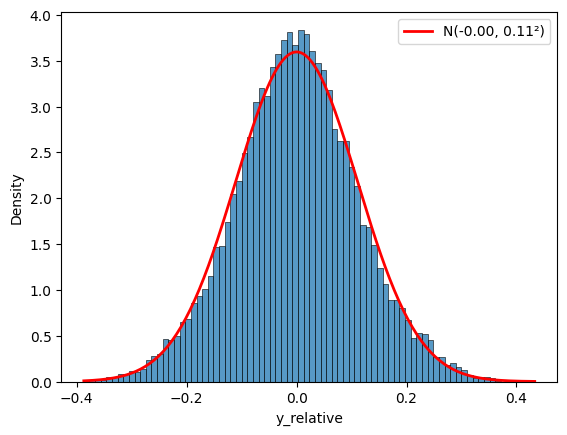

In [ ]:
# Prüfen, wie gut die Normalverteilung die Zielvariable approximiert
sns.histplot(y_train, stat="density")

# PDF der approximierten Normalverteilung berechnen
x = np.linspace(y_train.min(), y_train.max(), 200)
pdf = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)

# Kurve über das Histogramm legen
plt.plot(x, pdf, color="red", linewidth=2, label=f"N({mean:.2f}, {std:.2f}²)")
plt.legend()
plt.show()

## 5 Hyperparameter-Tuning

Die Intervalle stammen aus den Standardbereichen der jeweiligen Implementierung
und wurden dort erweitert, wo die beste Kombination am Rand eines Intervalls lag.
Für die linearen Modelle wird eine vollständige Rastersuche verwendet, für die
übrigen Modelle ist der Parameterraum dafür zu gross, weshalb eine Zufallssuche
zum Einsatz kommt.

In [12]:
# Kreuzvalidierung, Raster- und Zufallssuche
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV, ParameterSampler

In [13]:
# Kreuzvalidierung nach Quartalen gruppieren, sodass jedes Quartal vollständig
# in einem Fold liegt. Andernfalls wären die Long-Short Körbe innerhalb eines
# Folds unvollständig und das Modell könnte aus zeitgleichen Kursentwicklungen
# anderer Unternehmen lernen.
groups = X_train.index.to_series().str.split('_', expand=True)[[1, 2]].agg('_'.join, axis=1)
cv = GroupKFold(n_splits=5)

In [14]:
def long_short_scorer(estimator, X, y):
    """Scorer für GridSearchCV/RandomizedSearchCV: mittlere Long-Short Rendite je
    Quartal (höher = besser).

    Getunt wird bewusst nicht auf den quadratischen Prognosefehler, sondern auf
    die Zielgrösse der Arbeit. Das Training der Modelle selbst erfolgt weiterhin
    über den MSE, da die Long-Short Rendite als diskrete Grösse nicht
    differenzierbar ist.
    """

    y_pred = estimator.predict(X)
    q_ret, _, _, _ = long_short_returns(y_pred, y, df_filtered['move_next_qtr'], verbose=False)

    return q_ret.mean()

In [15]:
def sort_by_period(X, y):
    """Sortiert die Zeilen nach Quartal und gibt die Gruppengrössen zurück, wie
    sie die .fit()-Methode von Ranking-Modellen erwartet."""

    period = X.index.to_series().str.split('_', expand=True)[[1, 2]].agg('_'.join, axis=1)
    sorted_df = X.assign(period=period, target=y).sort_values('period')
    group_sizes = sorted_df.groupby('period').size().values

    return sorted_df[X.columns], sorted_df['target'], group_sizes

## 6 Lineare Regression

In [39]:
# Lineare Modelle mit L2- (Ridge) und L1-Regularisierung (Lasso).
# enable_metadata_routing erlaubt die Übergabe von groups an die CV-Varianten.
import sklearn
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV

sklearn.set_config(enable_metadata_routing=True)

In [ ]:
# Lineare Regression ohne Regularisierung als interpretierbare Referenz
linreg = LinearRegression()

linreg.fit(X_train, y_train)

y_pred_linreg = linreg.predict(X_test)

print("-- Linear Regression --")
long_short_returns(y_pred_linreg, y_test, df_filtered['move_next_qtr'])

-- Linear Regression --
Avg return/quarter: 6.2762%
Avg return/year: 30.0894%
Win rate: 93.3%
Cumulative return: 145.5639%
RMSE: 0.1186
MAE: 0.09496


In [ ]:
# Ridge: Rastersuche über das Gewicht des Strafterms alpha
ridge_grid = {'alpha': np.linspace(5, 10, 100)}

ridge_search = GridSearchCV(Ridge(), ridge_grid, scoring=long_short_scorer, cv=cv, n_jobs=-1)

ridge_search.fit(X_train, y_train, groups=groups)

print("Best Ridge params:", ridge_search.best_params_)
print(f"Best CV long-short return/period: {ridge_search.best_score_:.4%}")

Best Ridge params: {'alpha': np.float64(8.232323232323232)}
Best CV long-short return/period: 3.0812%


In [ ]:
# Bestes Ridge-Modell auf den Testdaten auswerten
y_pred_ridge_search = ridge_search.best_estimator_.predict(X_test)

print("-- Ridge (t) --")
long_short_returns(y_pred_ridge_search, y_test, df_filtered['move_next_qtr'])

-- Ridge (t) --
Avg return/quarter: 6.4390%
Avg return/year: 30.9248%
Win rate: 93.3%
Cumulative return: 151.3992%
RMSE: 0.1187
MAE: 0.095


In [ ]:
# Koeffizienten des getunten Ridge-Modells
print(ridge_search.best_estimator_.coef_)

[ 0.01876443 -0.00389854 -0.02168859 -0.00575183 -0.000904   -0.00011259
 -0.06007967  0.01096031 -0.00224966 -0.00881162  0.00115379  0.01062424
 -0.00053269  0.00554535  0.0033265  -0.03818128 -0.01049234  0.02462632
  0.08212415  0.01002841 -0.00417368 -0.02867392 -0.00900508 -0.01987485
 -0.03082822  0.02290853  0.00821896 -0.00614317  0.00603162 -0.01904292
 -0.00323768  0.0075596  -0.02780604  0.08936144 -0.0357497  -0.0095472 ]


In [36]:
# RidgeCV bestimmt alpha direkt in der Kreuzvalidierung (Zielgrösse MSE)
ridge = RidgeCV(alphas=np.linspace(5, 10, 100), cv=cv)

ridge.fit(X_train, y_train, groups=groups)

y_pred_ridge = ridge.predict(X_test)

print("-- Ridge --")
long_short_returns(y_pred_ridge, y_test, df_filtered['move_next_qtr'])

-- Ridge --
Avg return/quarter: 6.4%
Avg return/year: 31.0%
Win rate: 93.3%
Cumulative return: 151.8%
Std Dev: 0.05
Sharpe: 1.34
RMSE: 0.1187
MAE: 0.0950


In [31]:
# Von RidgeCV gewähltes alpha
ridge.alpha_

np.float64(8.333333333333334)

In [ ]:
# Lasso: Rastersuche über logarithmisch verteilte alpha-Werte
lasso_grid = {'alpha': np.logspace(-5, 1, 100)}

lasso_search = GridSearchCV(Lasso(max_iter=10000), lasso_grid, scoring=long_short_scorer, cv=cv, n_jobs=-1)

lasso_search.fit(X_train, y_train, groups=groups)

print("Best Lasso params:", lasso_search.best_params_)
print(f"Best CV long-short return/period: {lasso_search.best_score_:.4%}")

Best Lasso params: {'alpha': np.float64(6.135907273413175e-05)}
Best CV long-short return/period: 3.4128%


In [ ]:
# Bestes Lasso-Modell auf den Testdaten auswerten
y_pred_lasso_search = lasso_search.best_estimator_.predict(X_test)

print("-- Lasso (t) --")
long_short_returns(y_pred_lasso_search, y_test, df_filtered['move_next_qtr'])

-- Lasso (t) --
Avg return/quarter: 6.2031%
Avg return/year: 28.7156%
Win rate: 93.3%
Cumulative return: 142.9586%
RMSE: 0.1188
MAE: 0.09508


In [37]:
# LassoCV bestimmt alpha direkt in der Kreuzvalidierung (Zielgrösse MSE)
lasso = LassoCV(alphas=np.logspace(-5, 1, 100), cv=cv)

lasso.fit(X_train, y_train, groups=groups)

y_pred_lasso = lasso.predict(X_test)

print("-- Lasso --")
long_short_returns(y_pred_lasso, y_test, df_filtered['move_next_qtr'])

-- Lasso --
Avg return/quarter: 6.4%
Avg return/year: 30.6%
Win rate: 93.3%
Cumulative return: 148.5%
Std Dev: 0.05
Sharpe: 1.27
RMSE: 0.1187
MAE: 0.0950


In [ ]:
# Koeffizienten des Lasso-Modells; die L1-Regularisierung setzt Koeffizienten
# schwacher Features exakt auf null
print(lasso.coef_)

[ 0.         -0.         -0.         -0.         -0.00212109  0.
 -0.06124655  0.01015248 -0.         -0.00591991 -0.          0.00670818
  0.          0.00410073  0.00048162 -0.05449277 -0.00611227  0.01684877
  0.07079391  0.0055671  -0.00028921 -0.0143017  -0.00084927 -0.02158628
 -0.          0.01391217  0.         -0.         -0.         -0.01571056
 -0.          0.         -0.02891709  0.08464189 -0.0357097  -0.00017972]


### 6.1 Signifikanz und Multikollinearität

Die OLS-Statistik zeigt, welche Features einen statistisch signifikanten
Zusammenhang mit der Zielvariable aufweisen. Da die Sentiment-Dimensionen
untereinander korrelieren, wird die Interpretation der Koeffizienten zusätzlich
über den Variance Inflation Factor und die Korrelationsmatrix abgesichert.

In [ ]:
# statsmodels liefert die klassische OLS-Statistik mit p-Werten
import statsmodels.api as sm

In [ ]:
# OLS auf den Trainingsdaten: Koeffizienten, p-Werte und R²
X_with_const = sm.add_constant(X_train)  # Achsenabschnitt ergänzen
ols_model = sm.OLS(y_train, X_with_const).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:             y_relative   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     7.637
Date:                Thu, 06 Aug 2026   Prob (F-statistic):           2.79e-38
Time:                        09:30:04   Log-Likelihood:                 17093.
No. Observations:               21739   AIC:                        -3.411e+04
Df Residuals:                   21702   BIC:                        -3.382e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0630      0.041     

In [ ]:
# Variance Inflation Factor je Feature als Mass für Multikollinearität
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["feature"] = X_with_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_with_const.values, i)
                     for i in range(X_with_const.shape[1])]
print(vif_data)

            feature          VIF
0             const  3075.026650
1     relevant_mean     4.663955
2      relevant_min     3.624939
3      relevant_max     2.128249
4        clear_mean     5.174769
5         clear_min     3.107043
6         clear_max     1.759354
7   optimistic_mean    17.576987
8    optimistic_min     4.393507
9    optimistic_max     5.977203
10    specific_mean     4.644272
11     specific_min     2.682093
12     specific_max     2.089671
13    cautious_mean     4.054505
14     cautious_min     2.416447
15     cautious_max     1.825292
16   assertive_mean    15.542065
17    assertive_min     4.833953
18    assertive_max     2.841123
19     valence_mean    18.574853
20      valence_min     3.252117
21      valence_max     6.726466
22     arousal_mean     9.764336
23      arousal_min     2.758672
24      arousal_max     4.490484
25   dominance_mean    15.057607
26    dominance_min     4.447701
27    dominance_max     3.082904
28         relevant     2.685640
29        

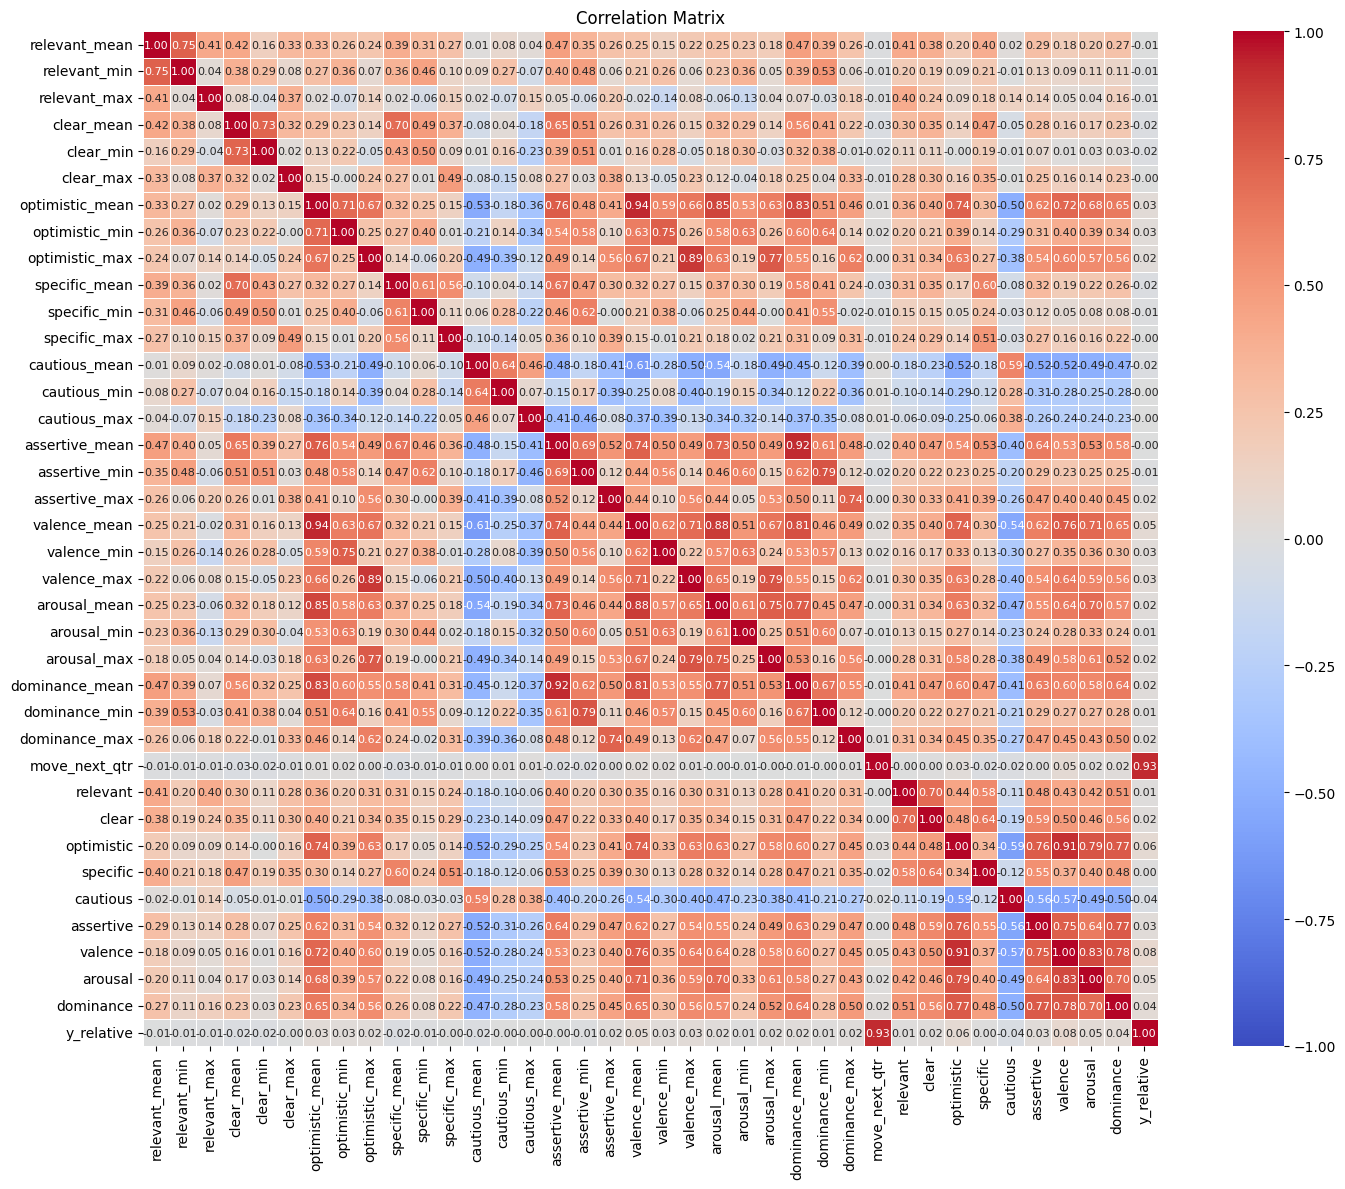

In [ ]:
# Korrelationen zwischen allen Features und der Zielvariable
corr = df_filtered.drop(columns=['ticker', 'year', 'quarter', 'period']).corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            annot_kws={"fontsize":8})
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2457/1829219387.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, orient='h', palette="Spectral")


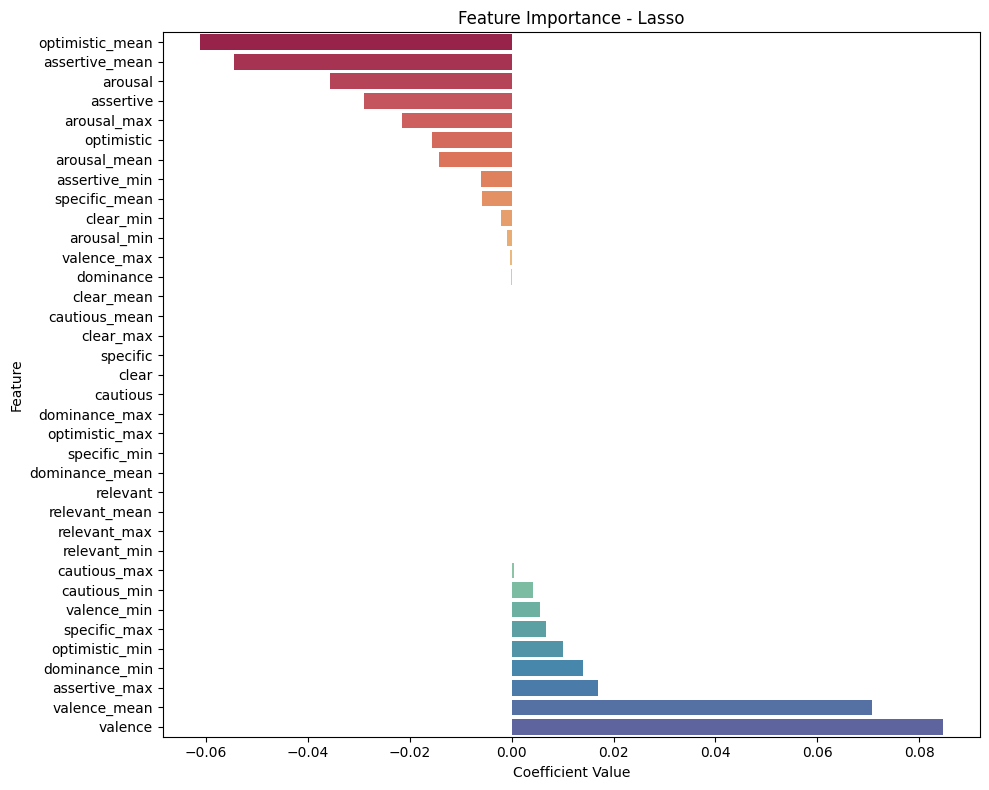

In [ ]:
# Koeffizienten als Mass für die Wichtigkeit der einzelnen Features
importances = pd.Series(lasso.coef_, index=X_train.columns).sort_values()

plt.figure(figsize=(10, 8))
sns.barplot(x=importances.values, y=importances.index, orient='h', palette="Spectral")
plt.title("Feature Importance - Lasso")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

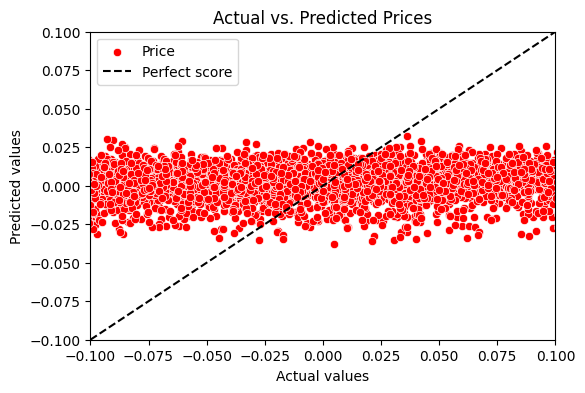

In [ ]:
# Tatsächliche gegen vorhergesagte Werte; die Diagonale entspricht der
# perfekten Vorhersage
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_test, y=y_pred_lasso, label='Price', color='red')

# Diagonale der perfekten Vorhersage
min_val = -0.1
max_val = 0.1
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', label='Perfect score')

plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

# Beschriftung
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs. Predicted Prices")
plt.legend()

# Ausgabe
plt.show()

## 7 Random Forest

In [ ]:
# Random Forest: Bagging über mehrere Entscheidungsbäume
from sklearn.ensemble import RandomForestRegressor

In [ ]:
# Random Forest: Zufallssuche über 40 Kombinationen. max_depth und
# min_samples_leaf begrenzen dabei das Overfitting.
forest_grid = {
    'n_estimators': [100, 200, 400, 600],
    'max_depth': [3, 5, 8, 12, None],
    'min_samples_leaf': [1, 5, 10, 25, 50],
    'min_samples_split': [2, 10, 20],
    'max_features': ['sqrt', 0.5, 0.8, 1.0],
}

forest_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1), forest_grid,
    n_iter=40, scoring=long_short_scorer, cv=cv, random_state=42, n_jobs=-1
)

forest_search.fit(X_train, y_train, groups=groups)

print("Best Random Forest params:", forest_search.best_params_)
print(f"Best CV long-short return/period: {forest_search.best_score_:.4%}")

Best Random Forest params: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': 5}
Best CV long-short return/period: 2.9582%


In [ ]:
# Bestes Random-Forest-Modell auf den Testdaten auswerten
y_pred_forest_search = forest_search.best_estimator_.predict(X_test)

print("-- Random Forest (t) --")
long_short_returns(y_pred_forest_search, y_test, df_filtered['move_next_qtr'])

-- Random Forest (t) --
Avg return/quarter: 5.3898%
Avg return/year: 24.6730%
Win rate: 93.3%
Cumulative return: 117.9593%
RMSE: 0.119
MAE: 0.09523


In [ ]:
# Random Forest in Standardkonfiguration, um den Beitrag des Tunings vom
# Beitrag der Modellklasse zu trennen
forest = RandomForestRegressor(random_state=42)

forest.fit(X_train, y_train)

y_pred_forest = forest.predict(X_test)

print("-- Random Forest --")
long_short_returns(y_pred_forest, y_test, df_filtered['move_next_qtr'])

-- Random Forest --
Avg return/quarter: 1.5283%
Avg return/year: 6.0739%
Win rate: 73.3%
Cumulative return: 25.2402%
RMSE: 0.1206
MAE: 0.09659


In [ ]:
# Zur Veranschaulichung eines einzelnen Entscheidungsbaums
from sklearn.tree import plot_tree

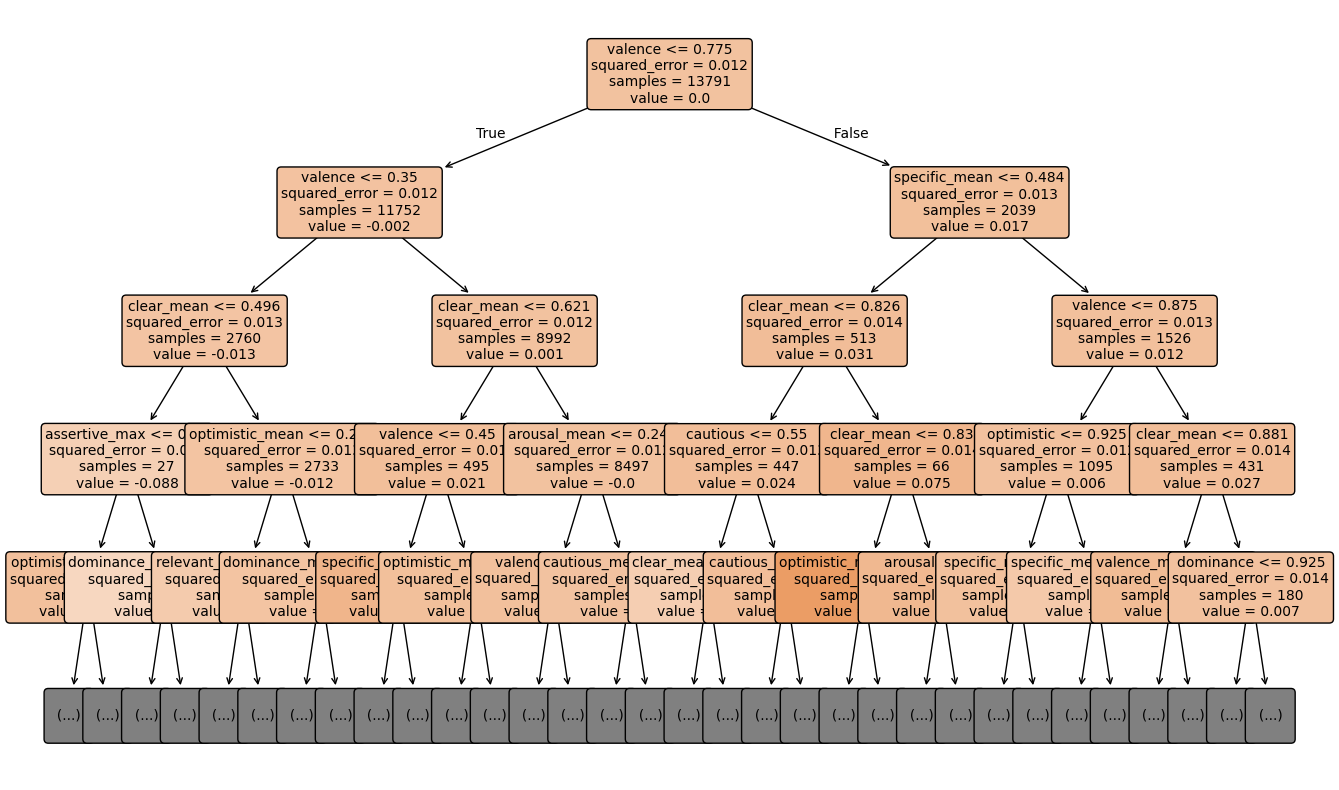

In [ ]:
# Ersten Baum des ungetunten Modells bis Tiefe 4 darstellen
tree_to_plot = forest.estimators_[0]

plt.figure(figsize=(16, 10))
plot_tree(tree_to_plot,
          feature_names=X_test.columns,
          filled=True,
          rounded=True,
          fontsize=10,
          max_depth=4)
plt.show()

In [ ]:
# Tiefe eines Baumes im ungetunten Modell
forest.estimators_[0].get_depth()

54

In [ ]:
# Tiefe eines Baumes im getunten Modell zum Vergleich
forest_search.best_estimator_.estimators_[0].get_depth()

5

## 8 XGBoost

In [ ]:
# XGBoost: Gradient Boosting, die Bäume werden sequenziell auf den
# verbleibenden Fehlern gebildet
from xgboost import XGBRegressor

In [ ]:
# XGBoost: Zufallssuche über 50 Kombinationen, inkl. L1- und L2-Straftermen
xgb_grid = {
    'n_estimators': [100, 200, 400],
    'max_depth': [2, 3, 4, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 5, 10, 20],
    'reg_alpha': [0, 0.1, 1, 5],
    'reg_lambda': [1, 5, 10, 20],
}

xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=1), xgb_grid,
    n_iter=50, scoring=long_short_scorer, cv=cv, random_state=42, n_jobs=-1
)

xgb_search.fit(X_train, y_train, groups=groups)

print("Best XGBoost params:", xgb_search.best_params_)
print(f"Best CV long-short return/period: {xgb_search.best_score_:.4%}")

Best XGBoost params: {'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 5, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best CV long-short return/period: 3.0211%


In [ ]:
# Bestes XGBoost-Modell auf den Testdaten auswerten
y_pred_xgb_search = xgb_search.best_estimator_.predict(X_test)

print("-- XGBoost (t) --")
long_short_returns(y_pred_xgb_search, y_test, df_filtered['move_next_qtr'])

-- XGBoost (t) --
Avg return/quarter: 4.9067%
Avg return/year: 21.4242%
Win rate: 93.3%
Cumulative return: 104.1031%
RMSE: 0.1189
MAE: 0.09511


In [ ]:
# XGBoost in Standardkonfiguration
xgb = XGBRegressor(random_state=42)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("-- XGBoost --")
long_short_returns(y_pred_xgb, y_test, df_filtered['move_next_qtr'])

-- XGBoost --
Avg return/quarter: 3.3480%
Avg return/year: 16.4896%
Win rate: 86.7%
Cumulative return: 60.6980%
RMSE: 0.1229
MAE: 0.09815


## 9 LightGBM

In [ ]:
# LightGBM: zweite Gradient-Boosting-Implementierung zum Vergleich
from lightgbm import LGBMRegressor

In [ ]:
# LightGBM: Zufallssuche über 50 Kombinationen; num_leaves steuert hier
# zusätzlich die Komplexität der Bäume
lgbm_grid = {
    'n_estimators': [100, 200, 400],
    'num_leaves': [7, 15, 31, 63],
    'max_depth': [3, 5, 8, -1],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'min_child_samples': [10, 20, 50, 100],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1, 5],
    'reg_lambda': [0, 0.1, 1, 5],
}

lgbm_search = RandomizedSearchCV(
    LGBMRegressor(random_state=42, verbose=-1, n_jobs=1), lgbm_grid,
    n_iter=50, scoring=long_short_scorer, cv=cv, random_state=42, n_jobs=-1
)

lgbm_search.fit(X_train, y_train, groups=groups)

print("Best LightGBM params:", lgbm_search.best_params_)
print(f"Best CV long-short return/period: {lgbm_search.best_score_:.4%}")

Best LightGBM params: {'subsample': 0.6, 'reg_lambda': 1, 'reg_alpha': 0.1, 'num_leaves': 7, 'n_estimators': 100, 'min_child_samples': 100, 'max_depth': -1, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best CV long-short return/period: 3.1477%


In [ ]:
# Bestes LightGBM-Modell auf den Testdaten auswerten
y_pred_lgbm_search = lgbm_search.best_estimator_.predict(X_test)

print("-- LightGBM (t) --")
long_short_returns(y_pred_lgbm_search, y_test, df_filtered['move_next_qtr'])

-- LightGBM (t) --
Avg return/quarter: 4.8278%
Avg return/year: 21.8486%
Win rate: 93.3%
Cumulative return: 101.1364%
RMSE: 0.1192
MAE: 0.09543


In [ ]:
# LightGBM in Standardkonfiguration
lgbm = LGBMRegressor(random_state=42, verbose=-1)

lgbm.fit(X_train, y_train)

y_pred_lgbm = lgbm.predict(X_test)

print("-- LightGBM --")
long_short_returns(y_pred_lgbm, y_test, df_filtered['move_next_qtr'])

-- LightGBM --
Avg return/quarter: 3.5633%
Avg return/year: 15.4813%
Win rate: 93.3%
Cumulative return: 68.2529%
RMSE: 0.1196
MAE: 0.09562


## 10 Neural Network

In [ ]:
# Multi-Layer-Perzeptron in einer Pipeline mit vorgeschalteter
# Standardisierung der Features
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
# Neural Network: Zufallssuche über Architektur, Regularisierung, Lernrate
# und Aktivierungsfunktion. Die Standardisierung ist nötig, da
# gradientenbasierte Verfahren empfindlich auf unterschiedliche Wertebereiche
# reagieren.
mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(random_state=42, max_iter=2000, early_stopping=True)),
])

mlp_grid = {
    'mlp__hidden_layer_sizes': [(32,), (64,), (32, 16), (64, 32), (64, 32, 16)],
    'mlp__alpha': np.logspace(-5, -1, 10),
    'mlp__learning_rate_init': [0.0001, 0.001, 0.005, 0.01],
    'mlp__activation': ['relu', 'tanh'],
}

mlp_search = RandomizedSearchCV(
    mlp_pipe, mlp_grid, n_iter=40, scoring=long_short_scorer, cv=cv, random_state=42, n_jobs=-1
)

mlp_search.fit(X_train, y_train, groups=groups)

print("Best Neural Network params:", mlp_search.best_params_)
print(f"Best CV long-short return/period: {mlp_search.best_score_:.4%}")

Best Neural Network params: {'mlp__learning_rate_init': 0.0001, 'mlp__hidden_layer_sizes': (64, 32, 16), 'mlp__alpha': np.float64(0.1), 'mlp__activation': 'tanh'}
Best CV long-short return/period: 3.1368%


In [ ]:
# Bestes Neural-Network-Modell auf den Testdaten auswerten
y_pred_mlp_search = mlp_search.best_estimator_.predict(X_test)

print("-- Neural Network (t) --")
long_short_returns(y_pred_mlp_search, y_test, df_filtered['move_next_qtr'])

-- Neural Network (t) --
Avg return/quarter: 6.1209%
Avg return/year: 30.0089%
Win rate: 93.3%
Cumulative return: 140.4314%
RMSE: 0.1188
MAE: 0.09508


In [ ]:
# Neural Network in Standardkonfiguration, ohne vorgeschaltete Standardisierung
mlp = MLPRegressor(random_state=42)

mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)

print("-- Neural Network --")
long_short_returns(y_pred_mlp, y_test, df_filtered['move_next_qtr'])

-- Neural Network --
Avg return/quarter: 4.3576%
Avg return/year: 18.9390%
Win rate: 93.3%
Cumulative return: 87.6507%
RMSE: 0.1191
MAE: 0.09519


## 11 Ergebnisse

In [ ]:
# Vorhersagen aller Modelle sammeln; "(t)" kennzeichnet die getunte Variante
models = {
    'Linear Regression':          y_pred_linreg,
    'Ridge (t)':                  y_pred_ridge_search,
    'Ridge':                      y_pred_ridge,
    'Lasso (t)':                  y_pred_lasso_search,
    'Lasso':                      y_pred_lasso,
    'Random Forest (t)':          y_pred_forest_search,
    'Random Forest':              y_pred_forest,
    'XGBoost (t)':                y_pred_xgb_search,
    'XGBoost':                    y_pred_xgb,
    'LightGBM (t)':               y_pred_lgbm_search,
    'LightGBM':                   y_pred_lgbm,
    'Neural Network (t)':         y_pred_mlp_search,
    'Neural Network':             y_pred_mlp,
}

In [ ]:
# Vorhersagen speichern; ausgewertet werden sie in "RESULTS Processing.ipynb"
pred_df = pd.DataFrame(models)

pred_df.to_csv('/content/drive/MyDrive/Bachelorarbeit/data/pred_v5.csv', index=False)

In [43]:
# Zielvariable und tatsächliche Renditen für die spätere Auswertung speichern
y_test.to_csv('/content/drive/MyDrive/Bachelorarbeit/data/y_test.csv', index=True)
df_filtered['move_next_qtr'].to_csv('/content/drive/MyDrive/Bachelorarbeit/data/y_actual.csv', index=True)

In [45]:
# joblib speichert die trainierten Modelle als Datei
import joblib

In [ ]:
# Alle trainierten Modelle speichern, damit sie in "GRAPH Processing.ipynb"
# ohne erneutes Training geladen werden können
save_dir = '/content/drive/MyDrive/Bachelorarbeit/models/'

model_objs = {
    'linreg': linreg, 'ridge_search': ridge_search.best_estimator_, 'ridge': ridge,
    'lasso_search': lasso_search.best_estimator_, 'lasso': lasso,
    'forest_search': forest_search.best_estimator_, 'forest': forest,
    'xgb_search': xgb_search.best_estimator_, 'xgb': xgb,
    'lgbm_search': lgbm_search.best_estimator_, 'lgbm': lgbm,
    'mlp_search': mlp_search.best_estimator_, 'mlp': mlp,
}

for name, model in model_objs.items():
    joblib.dump(model, f'{save_dir}{name}_v5.joblib')

### 11.1 Modelle nachträglich aktualisieren

Die Zellen dieses Abschnitts überschreiben gezielt einzelne gespeicherte
Modelle und Vorhersagen, ohne den gesamten Trainingslauf zu wiederholen.

In [46]:
# Nur die neu berechneten Ridge- und Lasso-Modelle überschreiben
joblib.dump(lasso, f'/content/drive/MyDrive/Bachelorarbeit/models/lasso_v5.joblib')
joblib.dump(ridge, f'/content/drive/MyDrive/Bachelorarbeit/models/ridge_v5.joblib')

['/content/drive/MyDrive/Bachelorarbeit/models/ridge_v5.joblib']

In [47]:
# Nur die Spalten der neu berechneten Modelle in der Vorhersagetabelle ersetzen
pred_df = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/pred_v5.csv')

pred_df['Lasso'] = y_pred_lasso
pred_df['Ridge'] = y_pred_ridge

pred_df.to_csv('/content/drive/MyDrive/Bachelorarbeit/data/pred_v5.csv', index=False)